# Everdingen-Hurst radial transient flow with `EverdingenHurst`

This notebook demonstrates the public `EverdingenHurst` class for radial diffusivity solutions inverted from Laplace space.

The class has two reservoir-engineering use cases:

- `pD(tD, ...)`: dimensionless well pressure for a constant-rate well.
- `qD(tD, ...)`: dimensionless flow rate for a constant-pressure well.

Each response can be evaluated for an infinite-acting reservoir or a closed circular reservoir with no flow at `rD = reD`.

## Engineering interpretation

For a constant-rate well, the plotted value is `pD`. A higher `pD` means a larger dimensionless pressure drop is required to maintain the same rate.

For a constant-pressure well, the plotted value is `qD`. A lower `qD` means the well rate has declined under the same wellbore drawdown.

Closed reservoirs depart from the infinite-acting curve after the pressure transient reaches the outer boundary. Smaller `reD` values feel the boundary earlier.

In [17]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np


def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in (start, *start.parents):
        if (path / "pyproject.toml").exists() and (path / "prodpy").exists():
            return path
    raise RuntimeError("Run this notebook from inside the production-data-analysis repository.")


repo_root = find_repo_root()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from prodpy.transient import EverdingenHurst
from prodpy.transient import InfiniteActing, PseudoSteadyState

In [7]:
tD = np.logspace(-3, 4, 60)
reD_values = [5, 10, 25]

# Stehfest degree 10 is a good interactive setting for this notebook.
# Use degree=12 when you want the package default.
degree = 10

## Constant-rate well: pressure response

This is the standard well-test pressure response. The well rate is fixed, and the graph shows the dimensionless wellbore pressure drop `pD(tD)`.

The infinite-acting curve represents a reservoir where the outer boundary has not been felt. The closed curves bend upward once the no-flow boundary affects the well response.

In [22]:
pD_infinite = np.asarray(
    EverdingenHurst.pD(tD, boundary="infinite", degree=degree)
)

pd_infinite_EI = np.asarray(
    InfiniteActing.pwD(tD)
)

pD_closed = {
    reD: np.asarray(
        EverdingenHurst.pD(tD, reD=reD, boundary="closed", degree=degree)
    )
    for reD in reD_values
}

pd_pss = np.asarray(
    PseudoSteadyState.prD(tD, 1, reD_values[2])
)

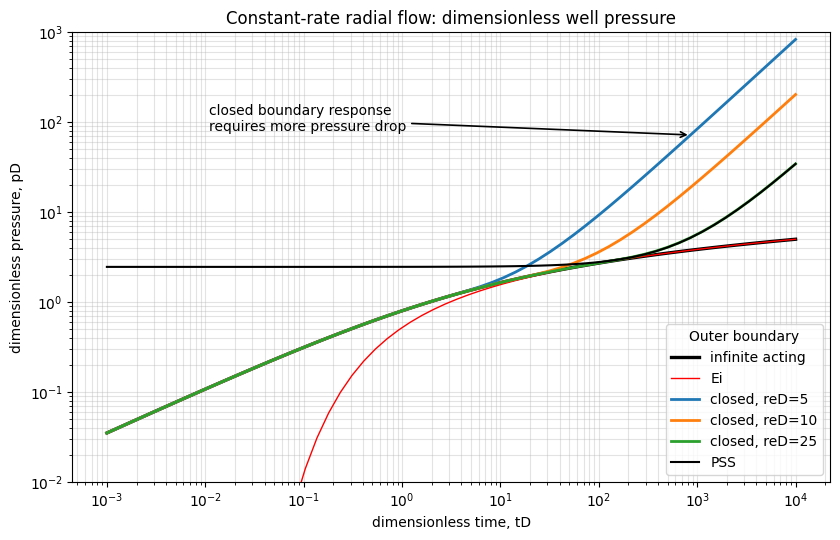

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))

ax.loglog(tD, pD_infinite, color="black", linewidth=2.4, label="infinite acting")
ax.loglog(tD, pd_infinite_EI, color="red", linewidth=1, label="Ei")
for reD, values in pD_closed.items():
    ax.loglog(tD, values, linewidth=2.0, label=f"closed, reD={reD}")
ax.loglog(tD, pd_pss, color = "k", label="PSS")

ax.set_title("Constant-rate radial flow: dimensionless well pressure")
ax.set_xlabel("dimensionless time, tD")
ax.set_ylabel("dimensionless pressure, pD")
ax.grid(True, which="both", alpha=0.35)
ax.legend(title="Outer boundary")

ax.annotate(
    "closed boundary response\nrequires more pressure drop",
    xy=(tD[-10], pD_closed[5][-10]),
    xytext=(0.18, 0.78),
    textcoords="axes fraction",
    arrowprops={"arrowstyle": "->", "linewidth": 1.2},
)

ax.set_ylim((1e-2,1e3))

fig.tight_layout()
plt.show()

## Constant-pressure well: rate decline

This is the complementary production response. The wellbore pressure is fixed, and the graph shows the dimensionless rate `qD(tD)`.

A closed reservoir has finite storage. After boundary effects arrive, the rate declines faster than the infinite-acting response. Smaller `reD` reaches that decline earlier.

In [5]:
qD_infinite = np.asarray(
    EverdingenHurst.qD(tD, boundary="infinite", degree=degree)
)

qD_closed = {
    reD: np.asarray(
        EverdingenHurst.qD(tD, reD=reD, boundary="closed", degree=degree)
    )
    for reD in reD_values
}

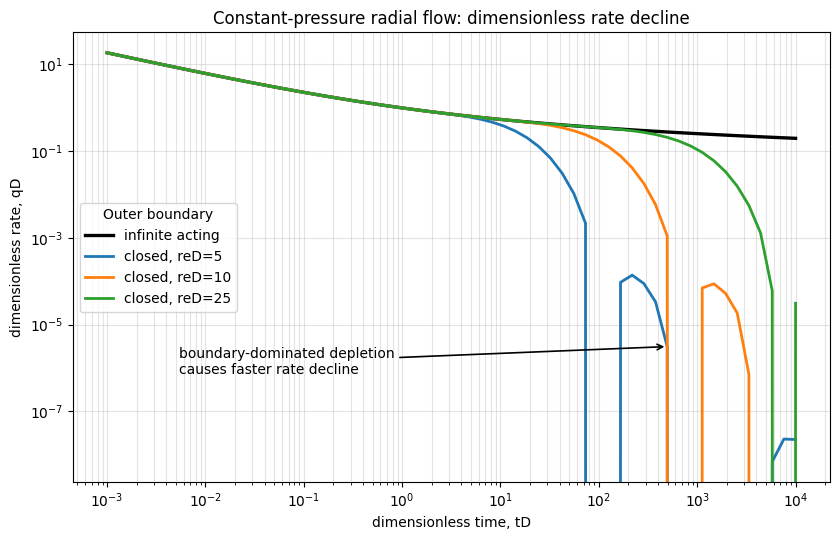

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))

ax.loglog(tD, qD_infinite, color="black", linewidth=2.4, label="infinite acting")
for reD, values in qD_closed.items():
    ax.loglog(tD, values, linewidth=2.0, label=f"closed, reD={reD}")

ax.set_title("Constant-pressure radial flow: dimensionless rate decline")
ax.set_xlabel("dimensionless time, tD")
ax.set_ylabel("dimensionless rate, qD")
ax.grid(True, which="both", alpha=0.35)
ax.legend(title="Outer boundary")

ax.annotate(
    "boundary-dominated depletion\ncauses faster rate decline",
    xy=(tD[-12], qD_closed[5][-12]),
    xytext=(0.14, 0.24),
    textcoords="axes fraction",
    arrowprops={"arrowstyle": "->", "linewidth": 1.2},
)

fig.tight_layout()
plt.show()

## Quick API reference

Use these calls when you need the time-domain Everdingen-Hurst well response:

```python
# constant-rate well, infinite acting reservoir
pD = EverdingenHurst.pD(tD, boundary="infinite")

# constant-rate well, closed circular reservoir
pD = EverdingenHurst.pD(tD, reD=10, boundary="closed")

# constant-pressure well, infinite acting reservoir
qD = EverdingenHurst.qD(tD, boundary="infinite")

# constant-pressure well, closed circular reservoir
qD = EverdingenHurst.qD(tD, reD=10, boundary="closed")
```

The default boundary for `pD` is `"infinite"`. The default boundary for `qD` is `"closed"` to preserve the original class behavior.